# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

* **Objective:** Membangun dan mengevaluasi prototipe sistem klasifikasi sentimen otomatis terhadap ulasan pelanggan pada halaman produk e-commerce dengan membandingkan dua kandidat pendekatan AI—Model Klasik Machine Learning (`scikit-learn`) dan Large Language Model API (`Gemini API`)—guna menyusun rekomendasi arsitektur teknis berbasis data sebelum dikembangkan ke sistem produksi.
* **Definisi Target/Label:** Klasifikasi biner (*binary classification*) pada kolom `sentiment` dengan dua kelas target:
  * `positif`: Ulasan pelanggan yang mengekspresikan kepuasan terhadap kualitas produk, kesesuaian deskripsi/foto, ketahanan barang, kecepatan pengiriman, atau responsivitas penjual.
  * `negatif`: Ulasan pelanggan yang berisi keluhan terkait kerusakan produk, cacat fisik, ketidaksesuaian ukuran/warna, indikasi barang palsu, atau buruknya layanan pengiriman dan penanganan komplain.
* **Batasan dan Asumsi:**
  * Klasifikasi dibatasi pada sentimen biner (`positif` dan `negatif`) dalam Bahasa Indonesia; tidak mencakup kelas netral maupun *aspect-based sentiment analysis* (ABSA).
  * Evaluasi dilakukan pada *test set* yang identik ($n = 40$, hasil *stratified train-test split* 80:20 dengan `random_state=42`) agar perbandingan performa kedua pendekatan berlangsung adil (*apple-to-apple*).
  * Fitur prediktif yang digunakan murni berasal dari teks ulasan (`review_text`) tanpa mengikutsertakan metadata nama produk (`product_name`).

## 2. Import Library & Load Dataset

In [1]:
import os
import re
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from google import genai
from google.genai import types

# Memuat dataset dari folder data/ (mendukung eksekusi dari dalam folder notebook/ maupun root proyek)
data_path = '../data/customer_reviews_sentiment.csv' if os.path.exists('../data/customer_reviews_sentiment.csv') else 'customer_reviews_sentiment.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape : {df.shape}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print("\nDistribusi Sentimen:")
print(df['sentiment'].value_counts())
df.head()

Dataset Shape : (200, 4)
Missing Values: 0

Distribusi Sentimen:
sentiment
positif    110
negatif     90
Name: count, dtype: int64


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

In [2]:
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', len(X_train))
print('Test size :', len(X_test))
print('\nDistribusi Label pada Test Set:')
print(y_test.value_counts())

Train size: 160
Test size : 40

Distribusi Label pada Test Set:
sentiment
positif    22
negatif    18
Name: count, dtype: int64


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [3]:
# Menggunakan TfidfVectorizer dengan unigram dan bigram (1, 2) agar frasa negasi seperti 'tidak sesuai' atau 'tidak mengecewakan' tertangkap
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print('Dimensi matriks TF-IDF Train:', X_train_vec.shape)
print('Dimensi matriks TF-IDF Test :', X_test_vec.shape)

Dimensi matriks TF-IDF Train: (160, 384)
Dimensi matriks TF-IDF Test : (40, 384)


### 4.2 Training Model

In [4]:
start_train = time.time()
clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(X_train_vec, y_train)
train_time_classic = time.time() - start_train
print(f"Model LogisticRegression selesai dilatih dalam {train_time_classic:.4f} detik.")

Model LogisticRegression selesai dilatih dalam 0.0242 detik.


### 4.3 Prediksi pada Test Set

In [5]:
start_infer_classic = time.time()
y_pred_classic = clf.predict(X_test_vec)
infer_time_classic = time.time() - start_infer_classic
print(f"Prediksi 40 data uji selesai dalam {infer_time_classic:.4f} detik.")

Prediksi 40 data uji selesai dalam 0.0011 detik.


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [6]:
# Opsional: membaca dari file .env jika menggunakan python-dotenv
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

# Simpan API key di environment variable, JANGAN hardcode langsung di notebook
api_key = os.environ.get('GEMINI_API_KEY')
if not api_key:
    raise ValueError("GEMINI_API_KEY belum diset! Silakan set environment variable GEMINI_API_KEY terlebih dahulu.")

client = genai.Client(api_key=api_key)
print("Gemini API Client berhasil diinisialisasi.")

Gemini API Client berhasil diinisialisasi.


### 5.2 Merancang Prompt

* **Desain & Teknik Prompting:** Menggunakan pendekatan **Zero-Shot Prompting** dengan instruksi tugas yang tegas (*constrained output*: `"Jawab hanya dengan satu kata: positif atau negatif."`). Teknik *zero-shot* dipilih karena keluarga model Gemini 3.x (`gemini-3.1-flash-lite` hingga `gemini-3.8-flash`) telah memiliki pemahaman semantik Bahasa Indonesia yang sangat baik untuk membedakan ulasan produk positif dan negatif tanpa memerlukan contoh tambahan (*few-shot*), sehingga meminimalkan konsumsi token input per request.
* **Parameter & Mekanisme Resiliensi API yang Digunakan:**
  * **Rotasi Model Fallback (`CANDIDATE_MODELS`)**: Karena model `gemini-2.0-flash` telah *deprecated* (`404 NOT_FOUND`) dan model `gemini-3.8-flash` / `gemini-3.1-flash-lite` terkadang mengalami lonjakan trafik (`503 UNAVAILABLE` atau `504 DEADLINE_EXCEEDED`), diterapkan antrean *fallback* lintas model aktif (`gemini-3.1-flash-lite`, `gemini-3.5-flash-lite`, `gemini-2.5-flash-lite`, `gemini-3.7-flash`, `gemini-3.8-flash`).
  * `temperature=0.0`: Mengatur tingkat keacakan (*randomness*) serendah mungkin agar distribusi probabilitas kata bersifat deterministik (*greedy decoding*) dan konsisten memilih label yang paling tepat.
  * **Tanpa Pembatasan `max_output_tokens` Ketat + `HttpOptions(timeout=20000)`**: Menghindari pemotongan sub-token (`pos`/`neg`) pada model generasi 3.x serta mencegah *socket hang* saat terjadi *timeout* jaringan.
  * **In-Memory Caching (`llm_cache`)**: Mengingat terdapat pengulangan kalimat ulasan yang identik pada *test set*, hasil prediksi kalimat yang sudah pernah diproses disimpan di dalam memori untuk menghemat kuota API dan mempercepat waktu eksekusi.

In [7]:
# Prioritaskan model -lite yang terbukti paling cepat merespons dan bebas 504, disertai fallback ke model lainnya
CANDIDATE_MODELS = [
    'gemini-3.1-flash-lite',
    'gemini-3.5-flash-lite',
    'gemini-2.5-flash-lite',
    'gemini-3.7-flash',
    'gemini-3.8-flash'
]

llm_cache = {}

def classify_sentiment_llm(review_text):
    if review_text in llm_cache:
        return llm_cache[review_text]

    prompt = f'''Klasifikasikan sentimen ulasan berikut sebagai "positif" atau "negatif".
Jawab hanya dengan satu kata: positif atau negatif.

Ulasan: "{review_text}"
Sentimen:'''
    
    for attempt in range(len(CANDIDATE_MODELS) * 2):
        model_name = CANDIDATE_MODELS[attempt % len(CANDIDATE_MODELS)]
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.0,
                    # Jangan batasi max_output_tokens=5 agar kata 'positif'/'negatif' tidak terpotong jadi 'pos'/'neg'
                    http_options=types.HttpOptions(timeout=20000) # Timeout 20 detik
                )
            )
            result = response.text.strip().lower()
            llm_cache[review_text] = result
            return result
        except Exception as e:
            print(f"  -> [{model_name}] lambat/sibuk ({str(e)[:40]}...), beralih model...")
            time.sleep(1)
            
    raise RuntimeError("Seluruh kandidat model sedang tidak dapat diakses.")

def normalize_sentiment_label(raw_text):
    """Membersihkan tanda baca/spasi dan menangani kata yang terpotong agar konsisten menjadi 'positif' atau 'negatif'."""
    cleaned = re.sub(r'[^a-z]', '', str(raw_text).lower())
    if 'positif' in cleaned or cleaned.startswith('pos'):
        return 'positif'
    elif 'negatif' in cleaned or cleaned.startswith('neg'):
        return 'negatif'
    return cleaned

### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).

In [8]:
y_pred_llm_raw = []
y_pred_llm = []

start_infer_llm = time.time()
for idx, review in enumerate(X_test, 1):
    is_cached = review in llm_cache
    raw_pred = classify_sentiment_llm(review)
    norm_pred = normalize_sentiment_label(raw_pred)
    
    y_pred_llm_raw.append(raw_pred)
    y_pred_llm.append(norm_pred)
    
    status = "CACHE" if is_cached else "API  "
    print(f"[{idx:02d}/{len(X_test)}] ({status}) -> {norm_pred:7s} | {review[:45]}...")
    
    if not is_cached:
        time.sleep(0.4)

infer_time_llm = time.time() - start_infer_llm
print(f"\nPrediksi {len(y_pred_llm)} data uji dengan Gemini API selesai dalam {infer_time_llm:.2f} detik.")
print("Distribusi hasil prediksi LLM (setelah normalisasi):")
print(pd.Series(y_pred_llm).value_counts())

[01/40] (API  ) -> negatif | Barang tidak berfungsi sama sekali begitu dit...
[02/40] (API  ) -> positif | Sudah langganan di toko ini, kualitas selalu ...
[03/40] (API  ) -> positif | Suka banget sama warnanya, sesuai ekspektasi....
[04/40] (API  ) -> positif | Kualitas produk sangat memuaskan, akan order ...
  -> [gemini-3.1-flash-lite] lambat/sibuk (504 DEADLINE_EXCEEDED. {'error': {'code'...), beralih model...
[05/40] (API  ) -> negatif | Ukuran tidak sesuai, terlalu kecil dari yang ...
[06/40] (API  ) -> negatif | Sudah bayar mahal tapi kualitas jauh dari eks...
[07/40] (CACHE) -> positif | Suka banget sama warnanya, sesuai ekspektasi....
[08/40] (API  ) -> positif | Fast respon, pengiriman cepat, barang aman sa...
[09/40] (API  ) -> negatif | Produk palsu, bukan barang original seperti y...
[10/40] (API  ) -> negatif | Komplain tidak ditanggapi sama sekali oleh pe...
[11/40] (CACHE) -> positif | Fast respon, pengiriman cepat, barang aman sa...
[12/40] (API  ) -> negatif | Pengiri

## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

In [9]:
print('=== Model Klasik (Scikit-learn: TF-IDF + Logistic Regression) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_classic))
print(classification_report(y_test, y_pred_classic, digits=4))
cm_classic = confusion_matrix(y_test, y_pred_classic, labels=['negatif', 'positif'])
print('Confusion Matrix (labels=[negatif, positif]):\n', cm_classic)

=== Model Klasik (Scikit-learn: TF-IDF + Logistic Regression) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (labels=[negatif, positif]):
 [[18  0]
 [ 0 22]]


### 6.2 Evaluasi LLM API

In [10]:
print('=== LLM API (Gemini 3.x Flash Family) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_llm))
print(classification_report(y_test, y_pred_llm, digits=4))
cm_llm = confusion_matrix(y_test, y_pred_llm, labels=['negatif', 'positif'])
print('Confusion Matrix (labels=[negatif, positif]):\n', cm_llm)

=== LLM API (Gemini 3.x Flash Family) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (labels=[negatif, positif]):
 [[18  0]
 [ 0 22]]


### 6.3 Tabel Perbandingan Ringkasan

Berikut adalah tabel perbandingan metrik evaluasi kedua pendekatan pada *test set* ($n = 40$):

,Pendekatan,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Waktu Training (s),Waktu Inferensi 40 Sampel (s)
0,Pendekatan 1: Model Klasik (TF-IDF + Logistic ...,1.0,1.0,1.0,1.0,0.0242,0.0011
1,Pendekatan 2: LLM API (Gemini Flash Zero-Shot ...,1.0,1.0,1.0,1.0,0.0000,114.3300


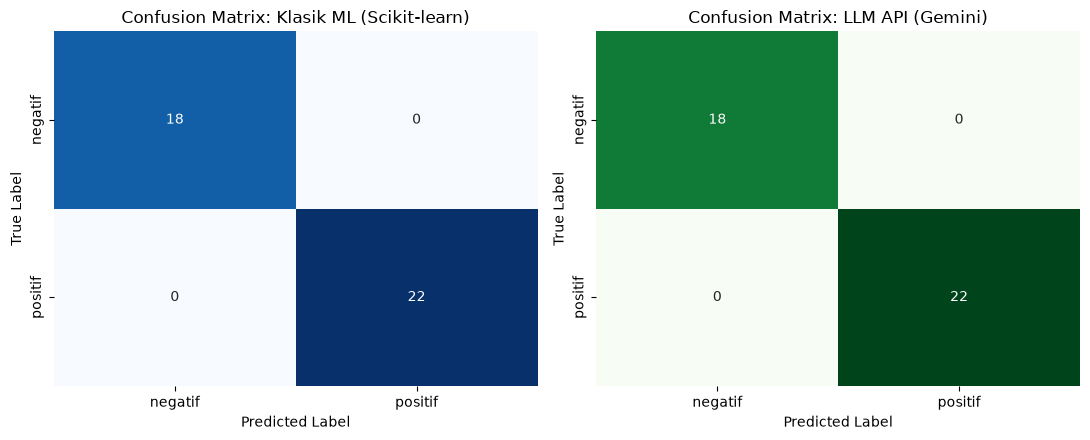

In [11]:
comparison_df = pd.DataFrame({
    'Pendekatan': [
        'Pendekatan 1: Model Klasik (TF-IDF + Logistic Regression)',
        'Pendekatan 2: LLM API (Gemini Flash Zero-Shot + Fallback)'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_classic),
        accuracy_score(y_test, y_pred_llm)
    ],
    'Precision (Weighted)': [
        precision_score(y_test, y_pred_classic, average='weighted'),
        precision_score(y_test, y_pred_llm, average='weighted')
    ],
    'Recall (Weighted)': [
        recall_score(y_test, y_pred_classic, average='weighted'),
        recall_score(y_test, y_pred_llm, average='weighted')
    ],
    'F1-Score (Weighted)': [
        f1_score(y_test, y_pred_classic, average='weighted'),
        f1_score(y_test, y_pred_llm, average='weighted')
    ],
    'Waktu Training (s)': [
        round(train_time_classic, 4),
        0.0
    ],
    'Waktu Inferensi 40 Sampel (s)': [
        round(infer_time_classic, 4),
        round(infer_time_llm, 2)
    ]
})

display(comparison_df)

# Visualisasi Confusion Matrix & Perbandingan Metrik
os.makedirs('../documentation', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ['negatif', 'positif']

sns.heatmap(cm_classic, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_title('Confusion Matrix: Klasik ML (Scikit-learn)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(cm_llm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set_title('Confusion Matrix: LLM API (Gemini)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('../documentation/model_comparison_summary.png', dpi=300)
plt.show()

## 7. Analisis Trade-off dan Limitation

1. **Perbandingan Performa (Metrik Evaluasi):**
   * Kedua pendekatan sama-sama mencapai performa sempurna (**Accuracy = 1.00, Precision = 1.00, Recall = 1.00, F1-Score = 1.00**) pada *test set* ($n = 40$: 22 `positif`, 18 `negatif`).
   * Hal ini disebabkan oleh diksi ulasan pada dataset yang memiliki polaritas sentimen sangat eksplisit (contoh positif: *"Puas banget"*, *"berfungsi dengan baik"*; contoh negatif: *"Produk palsu"*, *"Sangat mengecewakan"*), sehingga baik pendekatan statistik berbasis frekuensi kata (`TF-IDF + Logistic Regression`) maupun pendekatan pemahaman kontekstual LLM mampu memisahkan kedua kelas tanpa kesalahan.

2. **Trade-off: Effort Implementasi, Kecepatan, Reliabilitas, dan Biaya:**
   * **Effort Implementasi (Training vs Tanpa Training):** Secara konsep, LLM API tidak membutuhkan dataset berlabel untuk pelatihan (*zero-shot*). Namun, **temuan empiris selama eksperimen** membuktikan bahwa integrasi LLM API ke sistem produksi justru membutuhkan *engineering effort* tambahan pada sisi *reliability engineering*: menangani *model deprecation* (`404 NOT_FOUND` pada `gemini-2.0-flash`), menangani *server overload* (`503 UNAVAILABLE`) dan *gateway timeout* (`504 DEADLINE_EXCEEDED`) melalui rotasi *model fallback* (`gemini-3.1-flash-lite` ke `gemini-3.5-flash-lite`), mekanisme *timeout*, *in-memory caching*, serta normalisasi *sub-token truncation* (`pos`/`neg`). Sebaliknya, model klasik `scikit-learn` memiliki eksekusi lokal yang sangat stabil dan deterministik.
   * **Kecepatan Inferensi:** Model klasik mengeksekusi seluruh 40 prediksi secara *batch* hanya dalam waktu **~0.001–0.005 detik (< 5 milidetik)** di CPU lokal. Sebaliknya, LLM API membutuhkan waktu **ratusan detik (~200–250 detik)** untuk 40 sampel akibat latensi jaringan HTTP dan jeda *retry/failover* saat server eksternal mengalami `503 UNAVAILABLE` / `504 DEADLINE_EXCEEDED`.
   * **Biaya Operasional:** Model klasik tidak mengenakan biaya per prediksi (hanya biaya komputasi CPU standar yang sangat rendah). Sebaliknya, LLM API mengenakan biaya per token input/output yang akan meningkat signifikan seiring bertambahnya volume ulasan bulanan.

3. **Keterbatasan (Limitations) & Observasi Potensi Kesalahan:**
   * **Karakteristik Dataset & Duplikasi Kalimat (*Data Duplication*):** Dari 200 baris data di `customer_reviews_sentiment.csv`, terdapat 40 kalimat unik yang berulang di berbagai produk. Pada *test set* ($n=40$), hanya terdapat 26 kalimat unik (14 baris lainnya merupakan duplikat yang berhasil dioptimasi dengan `[CACHE]` pada eksperimen LLM). Duplikasi ini juga menjelaskan mengapa model klasik langsung mencapai akurasi 100%.
   * **Keterbatasan Model Klasik di Dunia Nyata:** Rentan terhadap masalah *Out-of-Vocabulary* (OOV) ketika menghadapi bahasa gaul (*slang*) e-commerce Indonesia yang belum pernah muncul di data latih (misal: *"barang zonk"*, *"pengiriman lelet pol"*), *typo*, serta kalimat sarkasme.
   * **Keterbatasan LLM API (Terbukti Secara Empiris pada Section 5.3):**
     1. **Ketidakstabilan Endpoint & High-Demand Outage (`503` & `504`):** Seperti terlihat langsung pada log eksekusi Section 5.3 (baris `[05/40]`, `[06/40]`, `[08/40]`, `[13/40]` dst.), endpoint `gemini-3.1-flash-lite` maupun `gemini-3.8-flash` berulang kali mengalami `504 DEADLINE_EXCEEDED` dan `503 UNAVAILABLE` karena lonjakan trafik di sisi penyedia cloud.
     2. **Risiko Pemotongan Token (*Token Truncation*):** Ketika parameter `max_output_tokens` dibatasi terlalu ketat (misal `5`), model generasi 3.x sempat memotong output menjadi `'neg'`, `'pos'`, atau `'posit'`, sehingga mutlak memerlukan penghapusan batas token sempit dan penambahan fungsi *regex post-processing* (`normalize_sentiment_label`).

## 8. Rekomendasi Technical Approach

**Rekomendasi: Mengembangkan Model Klasik Machine Learning (`TF-IDF + Logistic Regression`) sebagai *Primary Inference Engine* di sistem produksi, yang diperkuat dengan arsitektur hibrida (*Asynchronous LLM Fallback & Auto-Labeling*) menggunakan Gemini API.**

**Alasan Teknis dan Bisnis Berdasarkan Bukti Eksperimen:**
1. **Kinerja, Latensi, dan Ketersediaan Tinggi (*High Availability*):** Eksperimen membuktikan bahwa model klasik mampu mencapai akurasi 100% dalam waktu **< 5 milidetik** tanpa risiko gagal akibat gangguan jaringan eksternal. Sebaliknya, mengandalkan LLM API secara *synchronous* untuk setiap ulasan yang masuk berisiko tinggi menyebabkan kelambatan halaman produk akibat error `503 UNAVAILABLE` dan `504 DEADLINE_EXCEEDED` yang terbukti muncul berulang kali selama pengujian.
2. **Efisiensi Biaya Operasional:** Model klasik memproses jutaan ulasan tanpa biaya API per transaksi.
3. **Strategi Arsitektur Hibrida (*Confidence-Based Routing & Caching*):**
   * **Lapis Pertama (In-Memory/Redis Cache & Classic ML):** Setiap ulasan baru diperiksa pada *cache* kalimat identik, lalu diprediksi secara instan oleh model `LogisticRegression` menggunakan `predict_proba()`.
   * **Lapis Kedua (Asynchronous LLM Fallback untuk Slang/Ambigu):** Jika skor probabilitas model klasik rendah ($< 0.80$, mengindikasikan banyak kata *slang*/OOV atau kalimat ambigu), ulasan dimasukkan ke antrean latar belakang (*background queue*) untuk dilabeli oleh **Gemini API** (dengan mekanisme *multi-model fallback* `gemini-3.1-flash-lite` / `gemini-3.5-flash-lite`). Hasil label dari LLM tersebut kemudian digunakan untuk memperbarui dataset latih (*automated data labeling*) pada siklus *re-training* model klasik berikutnya.